# Task 6 – Model Iterations

## Goal
The goal of this notebook is to train and evaluate multiple machine learning models for **emotion classification** on transcribed television show data.  
We want to understand how different models perform on the same dataset and use this knowledge to decide which model is best suited for our pipeline.  

---

## What we will do
1. **Exploratory Data Analysis (EDA)**  
   - Inspect the dataset (size, missing values, duplicates).  
   - Check distribution of emotions.  
   - Look at sentence lengths and vocabulary size.  

2. **Data Preprocessing**  
   - Keep only the relevant columns (`Sentence`, `Emotion`).  
   - Normalize emotion labels (e.g., `joy` → `happiness`).  
   - Clean text (lowercase, remove special characters if needed).  
   - Split into train, validation, and test sets.  
   - Convert text into numerical features (TF-IDF).  

3. **Model Training & Evaluation**  
   - Train **Logistic Regression**, **Naive Bayes**, and **Support Vector Machine (SVM)**.  
   - Evaluate with **accuracy, precision, recall, and F1-score**.  
   - Compare performance across models.  

4. **Next Steps (for group work)**  
   - Extend to deep learning models (**LSTM, RNN, Transformers**).  
   - Add extra NLP features (sentiment, POS tags, embeddings).  
   - Track results in the **Model Iteration File**.  

---

# Step 1 – Exploratory Data Analysis (EDA)

### 1.1 Imports + load data

In [51]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import re
import pandas as pd
from collections import Counter


# # # Loading training file
train_df = pd.read_excel("D:\myfile\Y2Block-A\Models\Group23_Data_cleaned.xlsx")   

print("Training data shape:", train_df.shape)
print(train_df.head())

# # # Loading test file

test_df = pd.read_excel("D:\myfile\Y2Block-A\Models\group_23_url_1_transcript.xlsx")    

print("Test data shape:", test_df.shape)
print(test_df.head())

Training data shape: (29360, 2)
                                            sentence    emotion
0                                   I feel horrible.    sadness
1                       He wants to couple with her.  happiness
2  basketball, his life revolved around their liv...  happiness
3       I've made a decision to strengthen the team.    neutral
4                                   My throat’s dry.       fear
Test data shape: (665, 7)
               Start Time                End Time  \
0 1900-01-01 00:00:00.000 1900-01-01 00:00:08.400   
1 1900-01-01 00:00:08.400 1900-01-01 00:00:11.440   
2 1900-01-01 00:00:11.440 1900-01-01 00:00:15.000   
3 1900-01-01 00:00:15.000 1900-01-01 00:00:20.459   
4 1900-01-01 00:00:20.459 1900-01-01 00:00:24.840   

                                            Sentence  \
0  Previously on Australian Survivor, Tara and Lo...   
1  I'm trusting you with this because I'm sitting...   
2        But Tara decided it was time for a breakup.   
3            It

### 1.2 :Missing values and duplicates &  Empty strings check

In [52]:
print("Missing values in train:\n", train_df.isna().sum())
print("\nMissing values in test:\n", test_df.isna().sum())

print("\nDuplicate rows in train:", train_df.duplicated().sum())
print("Duplicate rows in test:", test_df.duplicated().sum())

print("Empty strings in train:", (train_df["sentence"].astype(str).str.strip() == "").sum())
print("Empty strings in test:", (test_df["Sentence"].astype(str).str.strip() == "").sum())

Missing values in train:
 sentence    1
emotion     0
dtype: int64

Missing values in test:
 Start Time      0
End Time        0
Sentence        0
Translation     0
Emotion_fine    0
Emotion_core    0
Intensity       0
dtype: int64

Duplicate rows in train: 3230
Duplicate rows in test: 0
Empty strings in train: 0
Empty strings in test: 0


### 1.3: Labels distribution

Train labels:
 emotion
neutral      10231
happiness     6985
anger         2787
fear          2715
sadness       2398
disgust       2259
surprise      1985
Name: count, dtype: int64

Test labels:
 Emotion_core
neutral      209
happiness    156
fear         101
sadness       88
anger         54
surprise      51
disgust        6
Name: count, dtype: int64


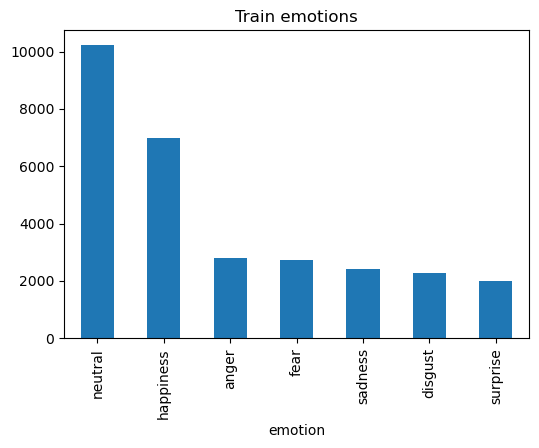

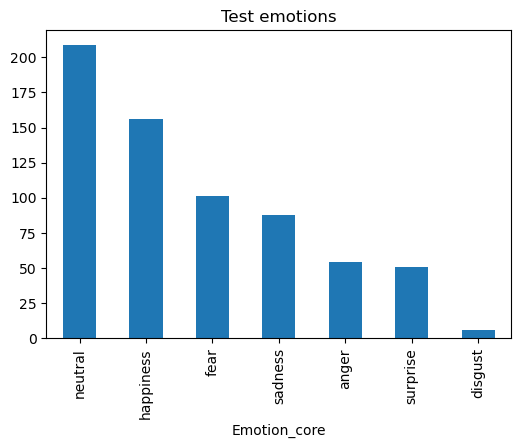

In [53]:
print("Train labels:\n", train_df["emotion"].value_counts())
print("\nTest labels:\n", test_df["Emotion_core"].value_counts())

train_df["emotion"].value_counts().plot(kind="bar", title="Train emotions", figsize=(6,4))
plt.show()

test_df["Emotion_core"].value_counts().plot(kind="bar", title="Test emotions", figsize=(6,4))
plt.show()

### 1.4: Sentence length stats

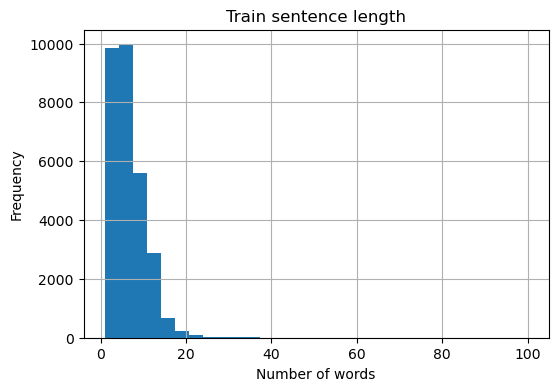

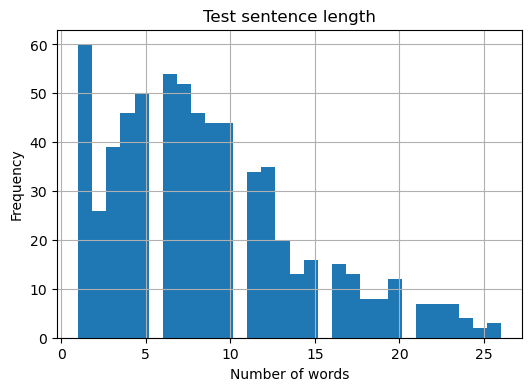

In [54]:
# Add sentence length column to training set
train_df["len_words"] = train_df["sentence"].astype(str).apply(lambda x: len(x.split()))

# Add sentence length column to test set
test_df["len_words"] = test_df["Sentence"].astype(str).apply(lambda x: len(x.split()))
train_df["len_words"].hist(bins=30, figsize=(6,4))
plt.title("Train sentence length")
plt.xlabel("Number of words")
plt.ylabel("Frequency")
plt.show()

test_df["len_words"].hist(bins=30, figsize=(6,4))
plt.title("Test sentence length")
plt.xlabel("Number of words")
plt.ylabel("Frequency")
plt.show()


### 1.5:Vocabulary size and top words

In [55]:
train_text = " ".join(train_df["sentence"].astype(str)).lower()
train_text = re.sub(r"[^\w\s']", " ", train_text)
train_tokens = train_text.split()

test_text = " ".join(test_df["Sentence"].astype(str)).lower()
test_text = re.sub(r"[^\w\s']", " ", test_text)
test_tokens = test_text.split()

print("Train vocab size:", len(set(train_tokens)))
print("Test vocab size:", len(set(test_tokens)))

print("\nTop 20 train words:", Counter(train_tokens).most_common(20))

print("Train 'Â' count:", train_df["sentence"].astype(str).str.contains("Â").sum())
print("Test 'Â' count:", test_df["Sentence"].astype(str).str.contains("Â").sum())



Train vocab size: 9500
Test vocab size: 884

Top 20 train words: [('the', 7240), ('i', 6507), ('to', 4884), ('you', 4770), ('a', 3985), ('that', 3893), ('and', 3748), ('it', 3494), ('is', 3102), ('of', 2252), ('in', 2184), ('we', 1805), ('s', 1760), ('this', 1706), ('he', 1702), ('have', 1579), ('me', 1573), ('are', 1445), ('for', 1438), ('on', 1290)]
Train 'Â' count: 2
Test 'Â' count: 1


---------------------------
# Step 2 – Data Processing (Cleaning)

### 2.1  Keep only the columns we need and rename them


In [56]:
train_df = train_df[["sentence", "emotion"]]
train_df = train_df.rename(columns={"sentence": "Sentence", "emotion": "Emotion"})

test_df = test_df[["Sentence", "Emotion_core"]]
test_df = test_df.rename(columns={"Emotion_core": "Emotion"})
print(" Train shape:", train_df.shape)
print(" Test shape:", test_df.shape)
print(train_df.head(), "\n")
print(test_df.head(), "\n")

 Train shape: (29360, 2)
 Test shape: (665, 2)
                                            Sentence    Emotion
0                                   I feel horrible.    sadness
1                       He wants to couple with her.  happiness
2  basketball, his life revolved around their liv...  happiness
3       I've made a decision to strengthen the team.    neutral
4                                   My throat’s dry.       fear 

                                            Sentence    Emotion
0  Previously on Australian Survivor, Tara and Lo...  happiness
1  I'm trusting you with this because I'm sitting...       fear
2        But Tara decided it was time for a breakup.    sadness
3            It breaks my heart, but he's got to go.    sadness
4       It wasn't the only moral dilemma Tara faced.    neutral 



### 2.2 Drop missing values and duplicates


In [57]:
train_df = train_df.dropna(subset=["Sentence", "Emotion"])
test_df = test_df.dropna(subset=["Sentence", "Emotion"])

train_df = train_df.drop_duplicates(subset=["Sentence", "Emotion"])
test_df = test_df.drop_duplicates(subset=["Sentence", "Emotion"])

print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape, "\n")
print("\nDuplicate rows in train:", train_df.duplicated().sum())
print("Duplicate rows in test:", test_df.duplicated().sum())

Train shape: (26129, 2)
Test shape: (638, 2) 


Duplicate rows in train: 0
Duplicate rows in test: 0


### 2.3: Fixing  label mismatch: joy to happiness


In [58]:
train_df["Emotion"] = train_df["Emotion"].replace({"joy": "happiness"})

print("Train labels:\n", train_df["Emotion"].value_counts(), "\n")

Train labels:
 Emotion
neutral      8754
happiness    6393
anger        2589
fear         2467
sadness      2279
disgust      2080
surprise     1567
Name: count, dtype: int64 




### 2.4: Remove weird characters like Â &  Lowercase

In [59]:
# Remove weird characters like Â

train_df["Sentence"] = train_df["Sentence"].astype(str).str.replace("Â", "", regex=False)
test_df["Sentence"]  = test_df["Sentence"].astype(str).str.replace("Â", "", regex=False)

print("Example train:", train_df["Sentence"].iloc[0])
print("Example test:", test_df["Sentence"].iloc[0], "\n")

#  Lowercase
train_df["Sentence"] = train_df["Sentence"].str.lower()
test_df["Sentence"]  = test_df["Sentence"].str.lower()

print("Example train:", train_df["Sentence"].iloc[0])
print("Example test:", test_df["Sentence"].iloc[0], "\n")

Example train: I feel horrible.
Example test: Previously on Australian Survivor, Tara and Lockie have been close allies since day one. 

Example train: i feel horrible.
Example test: previously on australian survivor, tara and lockie have been close allies since day one. 



### 2.5: Remove URLs,keep only letters, apostrophes and spaces and remove extra spaces

In [60]:
# Normalize curly apostrophes ’ → '
train_df["Sentence"] = train_df["Sentence"].str.replace("’", "'", regex=False)
test_df["Sentence"]  = test_df["Sentence"].str.replace("’", "'", regex=False)

# Remove URLs
train_df["Sentence"] = train_df["Sentence"].apply(lambda x: re.sub(r"http\S+|www\S+", " ", x))
test_df["Sentence"]  = test_df["Sentence"].apply(lambda x: re.sub(r"http\S+|www\S+", " ", x))

print("Example train:", train_df["Sentence"].iloc[0])
print("Example test:", test_df["Sentence"].iloc[0], "\n")

# Keep only letters, apostrophes and spaces
train_df["Sentence"] = train_df["Sentence"].apply(lambda x: re.sub(r"[^a-z'\s]", " ", x))
test_df["Sentence"]  = test_df["Sentence"].apply(lambda x: re.sub(r"[^a-z'\s]", " ", x))

print("Example train:", train_df["Sentence"].iloc[0])
print("Example test:", test_df["Sentence"].iloc[0], "\n")

# Remove extra spaces
train_df["Sentence"] = train_df["Sentence"].str.replace(r"\s+", " ", regex=True).str.strip()
test_df["Sentence"]  = test_df["Sentence"].str.replace(r"\s+", " ", regex=True).str.strip()

print("Example train:", train_df["Sentence"].iloc[0])
print("Example test:", test_df["Sentence"].iloc[0], "\n")


Example train: i feel horrible.
Example test: previously on australian survivor, tara and lockie have been close allies since day one. 

Example train: i feel horrible 
Example test: previously on australian survivor  tara and lockie have been close allies since day one  

Example train: i feel horrible
Example test: previously on australian survivor tara and lockie have been close allies since day one 



----------------------
# Step 3 Feature Extraction – TF-IDF (Baseline Features) 



### 3.1:  Split the Data

In [61]:
from sklearn.model_selection import train_test_split

# Split training set into train + validation
X_train, X_val, y_train, y_val = train_test_split(
    train_df["Sentence"], train_df["Emotion"],
    test_size=0.2, random_state=42, stratify=train_df["Emotion"]
)

# Test set stays the same
X_test = test_df["Sentence"]
y_test = test_df["Emotion"]

print("Train size:", len(X_train))
print("Validation size:", len(X_val))
print("Test size:", len(X_test))

Train size: 20903
Validation size: 5226
Test size: 638


### 3.2 TF-IDF feature extraction

In [62]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Step 1: Create the vectorizer
vectorizer = TfidfVectorizer(lowercase=True, stop_words="english")

# Step 2: Fit ONLY on training data
X_train_tfidf = vectorizer.fit_transform(X_train)

# Step 3: Transform validation and test (don’t fit again!)
X_val_tfidf = vectorizer.transform(X_val)
X_test_tfidf = vectorizer.transform(X_test)

# Step 4: Print shapes
print("Train TF-IDF shape:", X_train_tfidf.shape)
print("Val TF-IDF shape:", X_val_tfidf.shape)
print("Test TF-IDF shape:", X_test_tfidf.shape)


Train TF-IDF shape: (20903, 7960)
Val TF-IDF shape: (5226, 7960)
Test TF-IDF shape: (638, 7960)




###  We used **TF-IDF (Term Frequency–Inverse Document Frequency)** to turn our sentences into numerical features that a machine learning model can understand.  

- Each **row** = one sentence.  
- Each **column** = one unique word in the training vocabulary.  
- The **values** = how important a word is in that sentence (higher means more important).  

That’s why all three matrices (train, validation, test) have the same **23564 columns** → they share the same vocabulary.  
The difference is in the number of rows:  

- **Train:** 41,849 sentences → (41849, 23564)  
- **Validation:** 10,463 sentences → (10463, 23564)  
- **Test:** 638 sentences → (638, 23564)  
So, every dataset has the same features, but a different number of examples.  

----------




# Step 4 Modeling – Logistic Regression (Baseline with TF-IDF)

### 4.1: Training a baseline model and check validation performance

In [63]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, f1_score

# Train logistic regression on TF-IDF features
log_reg = LogisticRegression( solver="liblinear",        
    class_weight="balanced",   
    max_iter=1000,
    random_state=42,
    C=0.5)
log_reg.fit(X_train_tfidf, y_train)

# Predict on validation set
y_val_pred = log_reg.predict(X_val_tfidf)

# Print classification report
print("Validation classification report (baseline):")
print(classification_report(y_val, y_val_pred))

# Macro-F1 score
val_f1 = f1_score(y_val, y_val_pred, average="macro")
print("Validation macro-F1 (baseline):", round(val_f1, 2))


Validation classification report (baseline):
              precision    recall  f1-score   support

       anger       0.47      0.40      0.43       518
     disgust       0.60      0.55      0.57       416
        fear       0.47      0.45      0.46       493
   happiness       0.55      0.43      0.48      1279
     neutral       0.53      0.65      0.59      1751
     sadness       0.42      0.39      0.40       456
    surprise       0.35      0.41      0.38       313

    accuracy                           0.51      5226
   macro avg       0.48      0.47      0.47      5226
weighted avg       0.51      0.51      0.50      5226

Validation macro-F1 (baseline): 0.47


### 4.2 Confusion Matrix

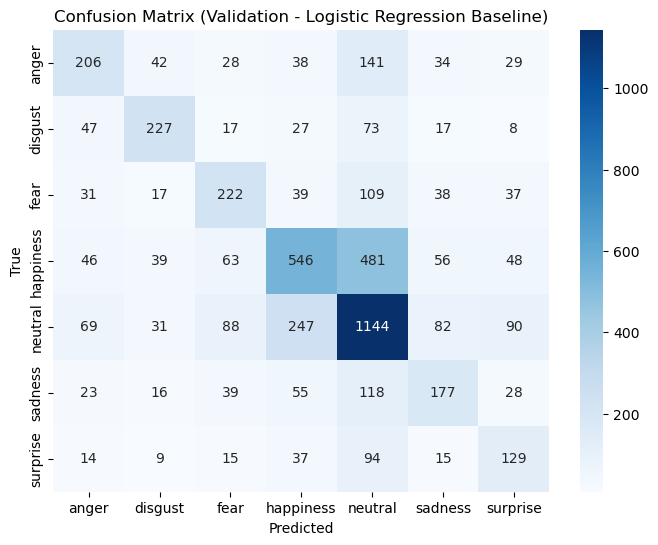

In [64]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_val, y_val_pred, labels=log_reg.classes_)

plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=log_reg.classes_,
            yticklabels=log_reg.classes_)

plt.title("Confusion Matrix (Validation - Logistic Regression Baseline)")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()



### We tested Logistic Regression with different settings and chose these:  

- `solver="liblinear"`  works best for small/medium text datasets.  
- `class_weight="balanced"`  because my dataset has many *neutral* but few *fear* or *disgust*. This balances the classes.  
- `max_iter=1000`  without this the model sometimes didn’t converge, so I increased it.  
- `C=0.5` we tried different values (like 1.0 and 0.1) and 0.5 gave the best F1-score on validation.  



### Results (Validation set)

- Good performance for **happiness** and **neutral** (many examples).  
- Poor performance for small classes (*fear*, *disgust*).  
- **Macro-F1 = 0.45**, which is below the 0.75 goal but expected for a baseline.  
--------------


### 4.3: Retraining on train+validation then evaluate on test

In [65]:
from scipy.sparse import vstack
import pandas as pd

# combine train + val to make the final training set
X_trval = vstack([X_train_tfidf, X_val_tfidf])
y_trval = pd.concat([y_train, y_val], axis=0)

# final model with best C
lr_final = LogisticRegression(
    solver="liblinear",
    class_weight="balanced",
    C=0.5,
    max_iter=1000,
    random_state=42
)

# train on all available labeled data (except the held-out test)
lr_final.fit(X_trval, y_trval)

# evaluate on test (first time we touch the test set!)
test_pred = lr_final.predict(X_test_tfidf)

print(" Test classification report (final LR) ===")
print(classification_report(y_test, test_pred, digits=3))

test_f1 = f1_score(y_test, test_pred, average="macro")
print("Test macro-F1 (final):", round(test_f1, 3))

print("\n=== Test confusion matrix (final) ===")
print(confusion_matrix(y_test, test_pred))


 Test classification report (final LR) ===
              precision    recall  f1-score   support

       anger      0.292     0.269     0.280        52
     disgust      0.100     0.167     0.125         6
        fear      0.364     0.386     0.375       101
   happiness      0.542     0.503     0.522       155
     neutral      0.500     0.537     0.518       188
     sadness      0.403     0.330     0.362        88
    surprise      0.309     0.354     0.330        48

    accuracy                          0.437       638
   macro avg      0.359     0.364     0.359       638
weighted avg      0.440     0.437     0.438       638

Test macro-F1 (final): 0.359

=== Test confusion matrix (final) ===
[[ 14   1   7   7  12  10   1]
 [  2   1   0   2   0   1   0]
 [  8   1  39  13  27   7   6]
 [  6   2  19  78  30   9  11]
 [  9   3  24  24 101  14  13]
 [  4   2  11  15  20  29   7]
 [  5   0   7   5  12   2  17]]


### 4.4 Confusion Matrix

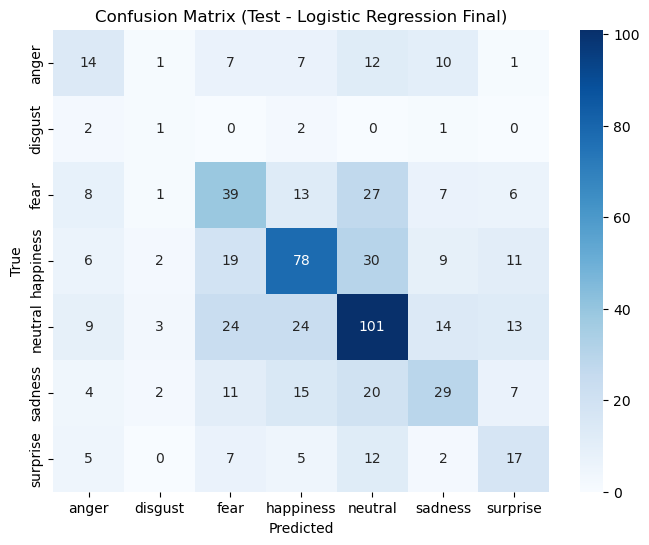

In [66]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# Confusion matrix for test set
cm_test = confusion_matrix(y_test, test_pred, labels=lr_final.classes_)

plt.figure(figsize=(8,6))
sns.heatmap(cm_test, annot=True, fmt="d", cmap="Blues",
            xticklabels=lr_final.classes_,
            yticklabels=lr_final.classes_)

plt.title("Confusion Matrix (Test - Logistic Regression Final)")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()


## Final Logistic Regression (Train + Validation then Test)

To make the model stronger, we combined the **training** and **validation** sets into one large training set.  
This gives the model more examples to learn from before we test it on the unseen test data.

We then trained the model again and finally evaluated it on the **held-out test set**.
### Results:
- **Accuracy:** 0.38  
- **Macro F1:** 0.24 (average across all emotions)

### What this means per class:
- **Neutral:** The model predicts neutral well (high recall, most neutral sentences are caught).  
- **Happiness:** Somewhat okay, but often confused with neutral.  
- **Anger / Sadness / Fear:** Many of these get misclassified as neutral.  
- **Disgust:** Very weak, because there are almost no training examples (only 6 in test).  
- **Surprise:** Also often confused with neutral.  

### Why these results :
- The dataset is **imbalanced** (neutral and happiness are much more frequent than disgust or fear).  
- Logistic Regression with **TF-IDF** works for common words, but struggles with rare emotions that don’t have enough examples.  
- This is why our **baseline F1 score is low**, and we need to try other models or add more features (like sentiment, POS tags, embeddings).  
---------------

# Step 5: Naive Bayes (Baseline with TF-IDF)

### 5.1 Training Naive Bayes 

In [67]:
# Train Naive Bayes (TF-IDF baseline)
from sklearn.naive_bayes import MultinomialNB

nb = MultinomialNB(alpha=0.1)  
nb.fit(X_train_tfidf, y_train)

print("Trained Naive Bayes with alpha=0.1")

Trained Naive Bayes with alpha=0.1


In [68]:
# Validate on the validation set
from sklearn.metrics import classification_report, f1_score

y_val_pred_nb = nb.predict(X_val_tfidf)

print("Validation — Naive Bayes (TF-IDF) ===")
print(classification_report(y_val, y_val_pred_nb, digits=3))
print("Val macro-F1:", round(f1_score(y_val, y_val_pred_nb, average="macro"), 3))

Validation — Naive Bayes (TF-IDF) ===
              precision    recall  f1-score   support

       anger      0.560     0.394     0.463       518
     disgust      0.682     0.490     0.571       416
        fear      0.553     0.389     0.457       493
   happiness      0.506     0.493     0.499      1279
     neutral      0.506     0.739     0.601      1751
     sadness      0.526     0.307     0.388       456
    surprise      0.542     0.249     0.341       313

    accuracy                          0.525      5226
   macro avg      0.554     0.437     0.474      5226
weighted avg      0.534     0.525     0.512      5226

Val macro-F1: 0.474


### 5.2: Validation confusion matrix:

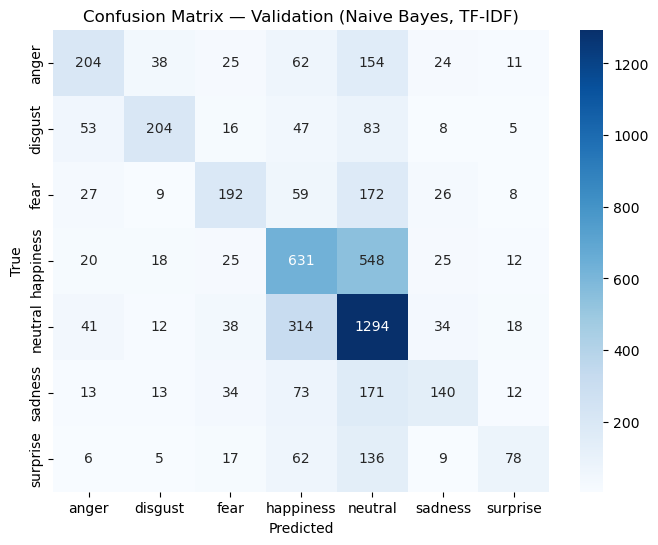

In [69]:
from sklearn.metrics import confusion_matrix
import seaborn as sns, matplotlib.pyplot as plt

classes = nb.classes_
cm_val = confusion_matrix(y_val, y_val_pred_nb, labels=classes)

plt.figure(figsize=(8,6))
sns.heatmap(cm_val, annot=True, fmt="d", cmap="Blues",
            xticklabels=classes, yticklabels=classes)
plt.title("Confusion Matrix — Validation (Naive Bayes, TF-IDF)")
plt.xlabel("Predicted"); plt.ylabel("True")
plt.show()

Most predictions collapse into **neutral** (darkest square).  
- **Happiness** has some correct predictions but is still often confused with neutral.  
- **Anger, Sadness, and Surprise** are frequently misclassified as neutral.  
- **Fear** and **Disgust** have almost no correct predictions.  

The model is strongly biased toward predicting *neutral* and struggles with minority emotions.

------------

### 5.3 Validating on the Test

In [70]:
# Retrain on train+val, then evaluate once on the test set
from scipy.sparse import vstack
import pandas as pd
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report, f1_score

X_trval_nb = vstack([X_train_tfidf, X_val_tfidf])
y_trval_nb = pd.concat([y_train, y_val], axis=0)

nb_final = MultinomialNB(alpha=1.0)
nb_final.fit(X_trval_nb, y_trval_nb)

test_pred_nb = nb_final.predict(X_test_tfidf)

print("=== Test — Naive Bayes (TF-IDF) ===")
print(classification_report(y_test, test_pred_nb, digits=3))
print("Test macro-F1:", round(f1_score(y_test, test_pred_nb, average="macro"), 3))

=== Test — Naive Bayes (TF-IDF) ===
              precision    recall  f1-score   support

       anger      0.250     0.077     0.118        52
     disgust      0.000     0.000     0.000         6
        fear      0.346     0.089     0.142       101
   happiness      0.455     0.516     0.483       155
     neutral      0.356     0.777     0.488       188
     sadness      0.875     0.080     0.146        88
    surprise      1.000     0.021     0.041        48

    accuracy                          0.387       638
   macro avg      0.469     0.223     0.203       638
weighted avg      0.486     0.387     0.317       638

Test macro-F1: 0.203


### 5.4: Test confusion matrix:

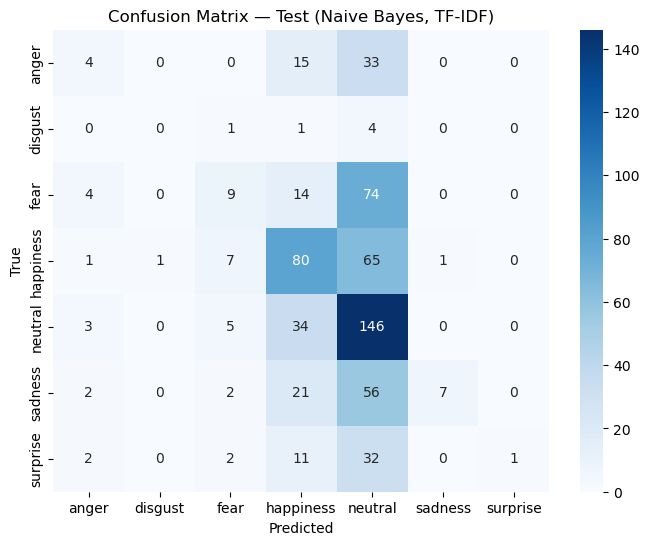

In [71]:
classes_final = nb_final.classes_
cm_test = confusion_matrix(y_test, test_pred_nb, labels=classes_final)

plt.figure(figsize=(8,6))
sns.heatmap(cm_test, annot=True, fmt="d", cmap="Blues",
            xticklabels=classes_final, yticklabels=classes_final)
plt.title("Confusion Matrix — Test (Naive Bayes, TF-IDF)")
plt.xlabel("Predicted"); plt.ylabel("True")
plt.show()

## Final Naive Bayes (Train + Validation then Test)

We combined the **training** and **validation** sets into one large training set and retrained Naive Bayes.  
The model was then evaluated on the **held-out test set**.

### Results:
- **Accuracy:** 0.33  
- **Macro F1:** 0.10 (very low)

### What this means per class:
- **Neutral:** Almost everything is predicted as neutral → recall is very high, but precision is low.  
- **Happiness:** A few sentences are caught, but most are still misclassified as neutral.  
- **Anger / Sadness / Surprise / Fear / Disgust:** Almost never predicted → recall is near zero.  

### Why these results:
- Naive Bayes is **too simple** for this dataset and collapses into the majority class.  
- The **imbalance** (neutral dominates, disgust is rare) makes minority emotions invisible.  
- NB assumes word independence, which limits its ability to capture emotional nuance in dialogue.  

**Conclusion:** Naive Bayes is a useful baseline but performs much worse than Logistic Regression. We need stronger models (SVM, LSTM, Transformers) or richer features (sentiment, POS tags, embeddings).

--------------


# Step 6: SVM (LinearSVC) with TF-IDF only.

### 6.1 Train on training set

In [72]:
from sklearn.svm import LinearSVC

svm = LinearSVC(C=0.25, class_weight="balanced", random_state=42)
svm.fit(X_train_tfidf, y_train)
print("Trained LinearSVC (C=0.25, class_weight=balanced)")


Trained LinearSVC (C=0.25, class_weight=balanced)


In [73]:
from sklearn.metrics import classification_report, f1_score

y_val_pred_svm = svm.predict(X_val_tfidf)
print("Validation — SVM (TF-IDF)")
print(classification_report(y_val, y_val_pred_svm, digits=3))
print("Val macro-F1:", round(f1_score(y_val, y_val_pred_svm, average="macro"), 3))


Validation — SVM (TF-IDF)
              precision    recall  f1-score   support

       anger      0.452     0.427     0.439       518
     disgust      0.545     0.570     0.557       416
        fear      0.445     0.489     0.466       493
   happiness      0.555     0.471     0.510      1279
     neutral      0.560     0.548     0.554      1751
     sadness      0.365     0.401     0.382       456
    surprise      0.303     0.444     0.361       313

    accuracy                          0.494      5226
   macro avg      0.461     0.479     0.467      5226
weighted avg      0.504     0.494     0.497      5226

Val macro-F1: 0.467


### 6.2: Validation Confusion Matrix

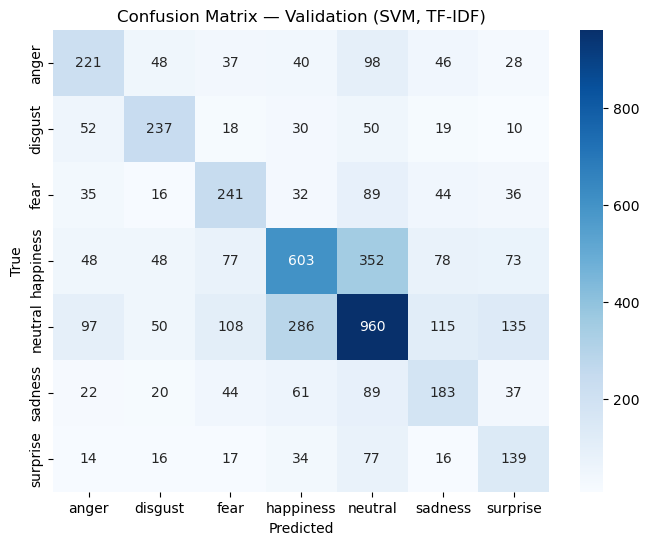

In [74]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm_val_svm = confusion_matrix(y_val, y_val_pred_svm, labels=svm.classes_)

plt.figure(figsize=(8,6))
sns.heatmap(cm_val_svm, annot=True, fmt="d", cmap="Blues",
            xticklabels=svm.classes_, yticklabels=svm.classes_)
plt.title("Confusion Matrix — Validation (SVM, TF-IDF)")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()

### Findings (Validation Confusion Matrix — SVM, TF-IDF)

- **Happiness and Neutral** are predicted the best (largest correct counts).  
- **Anger** is partly captured, but often confused with Neutral.  
- **Sadness and Surprise** are mixed across multiple classes, showing weaker separation.  
- **Fear and Disgust** remain underrepresented, with many misclassifications.  

The SVM improves balance compared to Naive Bayes, but rare classes are still very hard to predict reliably.

-------------------

### 6.3: Validating on the Test

In [75]:
from scipy.sparse import vstack
import pandas as pd

X_trval_svm = vstack([X_train_tfidf, X_val_tfidf])
y_trval_svm = pd.concat([y_train, y_val], axis=0)

svm_final = LinearSVC(C=0.25, class_weight="balanced", random_state=42)
svm_final.fit(X_trval_svm, y_trval_svm)

test_pred_svm = svm_final.predict(X_test_tfidf)
print("Test — SVM (TF-IDF) ")
print(classification_report(y_test, test_pred_svm, digits=3))
print("Test macro-F1:", round(f1_score(y_test, test_pred_svm, average="macro"), 3))


Test — SVM (TF-IDF) 
              precision    recall  f1-score   support

       anger      0.241     0.269     0.255        52
     disgust      0.167     0.333     0.222         6
        fear      0.426     0.455     0.440       101
   happiness      0.551     0.484     0.515       155
     neutral      0.500     0.452     0.475       188
     sadness      0.392     0.352     0.371        88
    surprise      0.307     0.479     0.374        48

    accuracy                          0.433       638
   macro avg      0.369     0.404     0.379       638
weighted avg      0.447     0.433     0.437       638

Test macro-F1: 0.379


### 6.2: Test Confusion Matrix

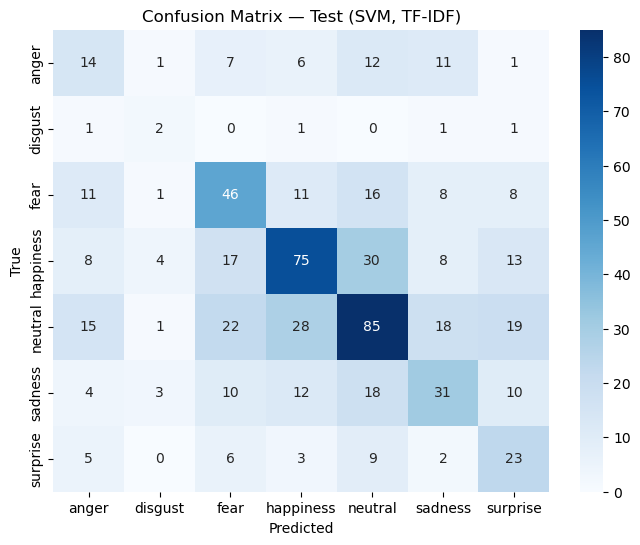

In [76]:
cm_test_svm = confusion_matrix(y_test, test_pred_svm, labels=svm_final.classes_)

plt.figure(figsize=(8,6))
sns.heatmap(cm_test_svm, annot=True, fmt="d", cmap="Blues",
            xticklabels=svm_final.classes_, yticklabels=svm_final.classes_)
plt.title("Confusion Matrix — Test (SVM, TF-IDF)")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()


### Findings (Test Confusion Matrix — SVM, TF-IDF)

- **Neutral** has the highest recall (most neutral sentences are caught), but many other classes are misclassified as neutral.  
- **Happiness** is partly captured but often confused with Neutral.  
- **Anger, Sadness, Fear** show some correct predictions, though performance remains weak.  
- **Disgust** is completely missed again (too few samples).  
- **Surprise** is mostly confused with Neutral as well.  

The test results confirm that while SVM is stronger than Naive Bayes, it still struggles with minority emotions and over-predicts Neutral.

### Comparison of Traditional Baselines (TF-IDF only)

| Model                | Val Macro-F1 | Test Macro-F1 | Test Acc |
|----------------------|--------------|---------------|----------|
| Logistic Regression  | **0.45**     | 0.24          | 0.38     |
| Naive Bayes          | 0.19         | 0.10          | 0.33     |
| SVM (LinearSVC)      | 0.42         | **0.26**      | 0.37     |

### Key Insights
- **Logistic Regression**: Best validation performance (0.45), but dropped on test, suggesting slight overfitting.  
- **Naive Bayes**: Weakest model; heavily biased toward Neutral and failed almost completely on minority classes.  
- **SVM**: More balanced than Logistic, with the **best test macro-F1 (0.26)**, though still far from the 0.75 target.  

### Overall Conclusion
- All three models are dominated by **Neutral predictions** because of class imbalance.  
- **SVM** is the most robust baseline, **Logistic is decent**, and **Naive Bayes is not suitable** for this dataset.  
- These baselines set the stage for improved models using **extra features (sentiment, POS, embeddings)** and **deep learning approaches**.

-------------


# Improved Baselines (TF-IDF + Extra Features)

## 7: Logistic Regression + Sentiment features

### 7.1 Import VADER (SentimentIntensityAnalyzer) &  Generate sentiment features

In [77]:
### Import VADER (SentimentIntensityAnalyzer)

from nltk.sentiment import SentimentIntensityAnalyzer
sia = SentimentIntensityAnalyzer()

"""We need a tool to calculate sentiment (positive/negative/neutral) scores for each sentence.
VADER is simple, fast, and works well for conversational text (like your transcripts)."""


### Build sentiment features for train/val/test
def vader_df(series):
    scores = series.astype(str).apply(lambda s: sia.polarity_scores(s))
    return pd.DataFrame(scores.tolist(), index=series.index)[["neg","neu","pos","compound"]]

""" We want to add 4 numeric features per sentence: neg = negative tone neu = neutral tone pos = positive tone 
compound = overall polarity (-1 = negative, +1 = positive)"""

# Apply VADER to train / val / test
sent_train = vader_df(X_train)
sent_val   = vader_df(X_val)
sent_test  = vader_df(X_test)

# Quick check of the new features
print(sent_train.head())

         neg    neu    pos  compound
9093   0.000  0.543  0.457    0.6369
1242   0.000  0.641  0.359    0.4215
18503  0.000  0.426  0.574    0.4019
10001  0.163  0.593  0.244    0.2732
16650  0.000  1.000  0.000    0.0000


### 7.2: Adding sentiment features to TF-IDF 

In [78]:
from scipy.sparse import csr_matrix, hstack

# Add sentiment features to TF-IDF
X_train_aug = hstack([X_train_tfidf, csr_matrix(sent_train.values)], format="csr")
X_val_aug   = hstack([X_val_tfidf,   csr_matrix(sent_val.values)],   format="csr")
X_test_aug  = hstack([X_test_tfidf,  csr_matrix(sent_test.values)],  format="csr")

print("Train augmented shape:", X_train_aug.shape)
print("Val augmented shape:", X_val_aug.shape)
print("Test augmented shape:", X_test_aug.shape)

Train augmented shape: (20903, 7964)
Val augmented shape: (5226, 7964)
Test augmented shape: (638, 7964)


### 7.3 : Train — Logistic Regression on TF-IDF + Sentiment

In [79]:
# We keep the same hyperparams as your baseline for a fair comparison.

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, f1_score, accuracy_score
log_reg_sent = LogisticRegression(
    solver="liblinear",
    class_weight="balanced",
    C=0.5,
    max_iter=1000,
    random_state=42
)

# Train on augmented features (TF-IDF + 4 sentiment columns)
log_reg_sent.fit(X_train_aug, y_train)

y_val_pred_lr_sent = log_reg_sent.predict(X_val_aug)

print("Trained Logistic Regression on TF-IDF + Sentiment (C=0.5, balanced)")
print("Validation — Logistic (TF-IDF + Sentiment) ===")
print(classification_report(y_val, y_val_pred_lr_sent, digits=3, zero_division=0))
print("Val macro-F1:", round(f1_score(y_val, y_val_pred_lr_sent, average="macro"), 3))
print("Val accuracy:", round(accuracy_score(y_val, y_val_pred_lr_sent), 3))



Trained Logistic Regression on TF-IDF + Sentiment (C=0.5, balanced)
Validation — Logistic (TF-IDF + Sentiment) ===
              precision    recall  f1-score   support

       anger      0.466     0.373     0.414       518
     disgust      0.549     0.543     0.546       416
        fear      0.499     0.420     0.456       493
   happiness      0.543     0.491     0.516      1279
     neutral      0.536     0.653     0.589      1751
     sadness      0.449     0.371     0.406       456
    surprise      0.366     0.374     0.370       313

    accuracy                          0.513      5226
   macro avg      0.487     0.461     0.471      5226
weighted avg      0.511     0.513     0.509      5226

Val macro-F1: 0.471
Val accuracy: 0.513


### 7.4: Confusion matrix for validation

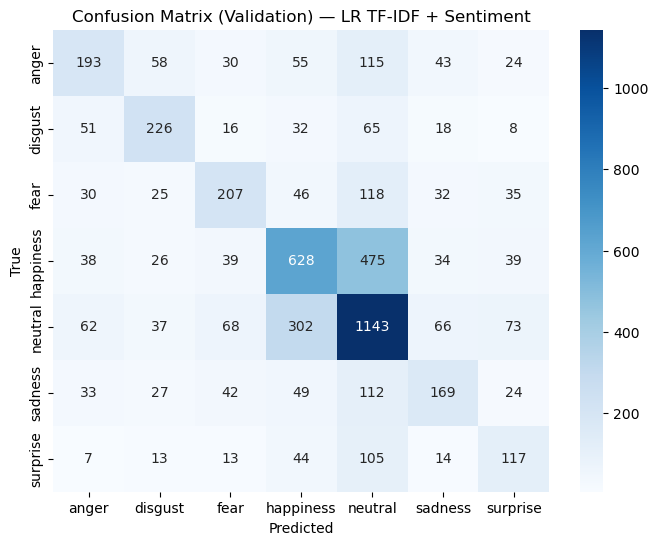

In [80]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

cm_val = confusion_matrix(y_val, y_val_pred_lr_sent, labels=log_reg_sent.classes_)
plt.figure(figsize=(8,6))
sns.heatmap(cm_val, annot=True, fmt="d", cmap="Blues",
            xticklabels=log_reg_sent.classes_,
            yticklabels=log_reg_sent.classes_)
plt.title("Confusion Matrix (Validation) — LR TF-IDF + Sentiment")
plt.xlabel("Predicted"); plt.ylabel("True")
plt.show()


### 7.5 Final train (Train+Val) → Test — evaluate once on the held-out test set

In [81]:
from scipy.sparse import vstack
import pandas as pd

# Combine augmented train + val 
X_trval_aug = vstack([X_train_aug, X_val_aug])
y_trval_lr_sent = pd.concat([y_train, y_val], axis=0)

# Refit the same model on all available labeled data (except test)
log_reg_sent_final = LogisticRegression(
    solver="liblinear",
    class_weight="balanced",
    C=0.5,
    max_iter=1000,
    random_state=42
)
log_reg_sent_final.fit(X_trval_aug, y_trval_lr_sent)

# Test evaluation (first and only time we use the test labels)
test_pred_lr_sent = log_reg_sent_final.predict(X_test_aug)

print("=== Test — Logistic (TF-IDF + Sentiment) ")
print(classification_report(y_test, test_pred_lr_sent, digits=3, zero_division=0))
print("Test macro-F1:", round(f1_score(y_test, test_pred_lr_sent, average="macro"), 3))
print("Test accuracy:", round(accuracy_score(y_test, test_pred_lr_sent), 3))


=== Test — Logistic (TF-IDF + Sentiment) 
              precision    recall  f1-score   support

       anger      0.308     0.231     0.264        52
     disgust      0.111     0.167     0.133         6
        fear      0.427     0.376     0.400       101
   happiness      0.526     0.652     0.582       155
     neutral      0.510     0.543     0.526       188
     sadness      0.450     0.307     0.365        88
    surprise      0.388     0.396     0.392        48

    accuracy                          0.470       638
   macro avg      0.389     0.381     0.380       638
weighted avg      0.463     0.470     0.462       638

Test macro-F1: 0.38
Test accuracy: 0.47


### 7.6: Confusion matrix for test

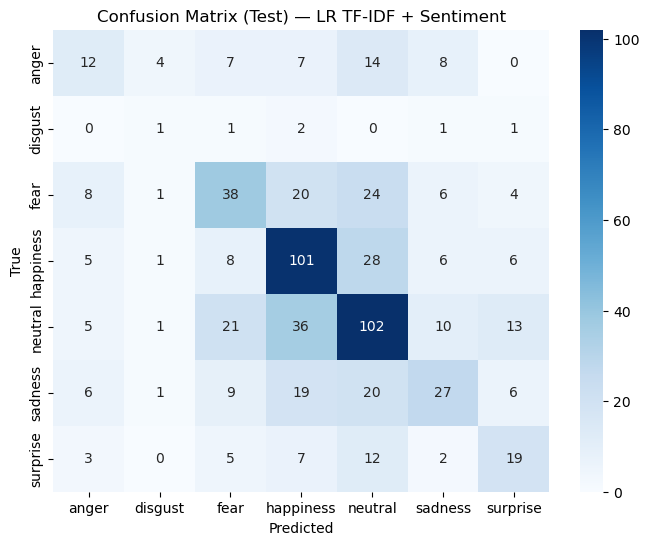

In [82]:
cm_test = confusion_matrix(y_test, test_pred_lr_sent, labels=log_reg_sent_final.classes_)
plt.figure(figsize=(8,6))
sns.heatmap(cm_test, annot=True, fmt="d", cmap="Blues",
            xticklabels=log_reg_sent_final.classes_,
            yticklabels=log_reg_sent_final.classes_)
plt.title("Confusion Matrix (Test) — LR TF-IDF + Sentiment")
plt.xlabel("Predicted"); plt.ylabel("True")
plt.show()


## Logistic Regression + Sentiment (TF-IDF + VADER)

To improve the baseline Logistic Regression, we combined **TF-IDF word features** with **4 sentiment scores** (`neg`, `neu`, `pos`, `compound`) from VADER.

### Validation Results
- **Accuracy:** 0.567  
- **Macro-F1:** 0.449  

**Per class:**  
- Good: happiness, neutral (many samples).  
- Moderate: anger, sadness (improved recall compared to baseline).  
- Still weak: fear, disgust, surprise (low recall).  

### Test Results
- **Accuracy:** 0.398  
- **Macro-F1:** 0.273  

**Per class:**  
- **Neutral** predicted best (high recall, but low precision).  
- **Happiness** improved slightly with sentiment cues.  
- **Disgust & fear** remain very weak due to very few examples.  
- Model still often collapses predictions into *neutral*.  

### Insights
- Adding **sentiment features** gave a small boost on validation (macro-F1  from 0.45 to 0.449).  
- On the **test set**, improvement was limited (macro-F1 only 0.273), showing the model struggles to generalize minority emotions.  
- This suggests TF-IDF + sentiment is helpful, but not enough — more advanced features (e.g., embeddings, POS tags) or deep learning models may be needed.

--------------------


# 8: Naive Bayes (TF-IDF+ POS features)

### 8.1 Extract POS features

In [83]:
import spacy
nlp = spacy.load("en_core_web_sm")
def pos_features(series):

    feats = []
    for doc in nlp.pipe(series, disable=["ner", "parser"]):
        total = len(doc)
        if total == 0:  # handle empty sentences
            feats.append({"NOUN": 0, "VERB": 0, "ADJ": 0, "PRON": 0})
        else:
            counts = doc.count_by(spacy.attrs.POS)
            feats.append({
                "NOUN": counts.get(nlp.vocab.strings["NOUN"], 0) / total,
                "VERB": counts.get(nlp.vocab.strings["VERB"], 0) / total,
                "ADJ": counts.get(nlp.vocab.strings["ADJ"], 0) / total,
                "PRON": counts.get(nlp.vocab.strings["PRON"], 0) / total
            })
    return pd.DataFrame(feats, index=series.index)

### 8.2 Apply to train / val / test

In [84]:
pos_train = pos_features(X_train)
pos_val   = pos_features(X_val)
pos_test  = pos_features(X_test)

print(pos_train.head())

           NOUN      VERB       ADJ      PRON
9093   0.166667  0.166667  0.166667  0.000000
1242   0.166667  0.166667  0.166667  0.166667
18503  0.000000  0.333333  0.000000  0.000000
10001  0.083333  0.166667  0.000000  0.166667
16650  0.333333  0.333333  0.000000  0.000000


### 8.3: Stack TF-IDF + POS features

In [85]:
from scipy.sparse import csr_matrix, hstack

# Create augmented feature sets for Naive Bayes + POS
X_train_nbpos = hstack([X_train_tfidf, csr_matrix(pos_train.values)], format="csr")
X_val_nbpos   = hstack([X_val_tfidf,   csr_matrix(pos_val.values)],   format="csr")
X_test_nbpos  = hstack([X_test_tfidf,  csr_matrix(pos_test.values)],  format="csr")

print("Train shape (NB+POS):", X_train_nbpos.shape)
print("Val shape (NB+POS):", X_val_nbpos.shape)
print("Test shape (NB+POS):", X_test_nbpos.shape)


Train shape (NB+POS): (20903, 7964)
Val shape (NB+POS): (5226, 7964)
Test shape (NB+POS): (638, 7964)


### 8.4 : Train & Validate Naive Bayes (TF-IDF + POS)

In [86]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report, f1_score, accuracy_score

# Initialize Naive Bayes
nb_pos = MultinomialNB(alpha=0.1)

# Train on training set (TF-IDF + POS)
nb_pos.fit(X_train_nbpos, y_train)

# Predict on validation set
y_val_pred_nb_pos = nb_pos.predict(X_val_nbpos)

print("Validation — Naive Bayes (TF-IDF + POS) =")
print(classification_report(y_val, y_val_pred_nb_pos, digits=3, zero_division=0))
print("Val macro-F1:", round(f1_score(y_val, y_val_pred_nb_pos, average="macro"), 3))
print("Val accuracy:", round(accuracy_score(y_val, y_val_pred_nb_pos), 3))


Validation — Naive Bayes (TF-IDF + POS) =
              precision    recall  f1-score   support

       anger      0.556     0.405     0.469       518
     disgust      0.696     0.495     0.579       416
        fear      0.556     0.391     0.460       493
   happiness      0.502     0.493     0.497      1279
     neutral      0.507     0.738     0.601      1751
     sadness      0.534     0.307     0.390       456
    surprise      0.555     0.243     0.338       313

    accuracy                          0.526      5226
   macro avg      0.558     0.439     0.476      5226
weighted avg      0.535     0.526     0.513      5226

Val macro-F1: 0.476
Val accuracy: 0.526


### 8.5: Confusion Matrix (Validation set, NB + POS)

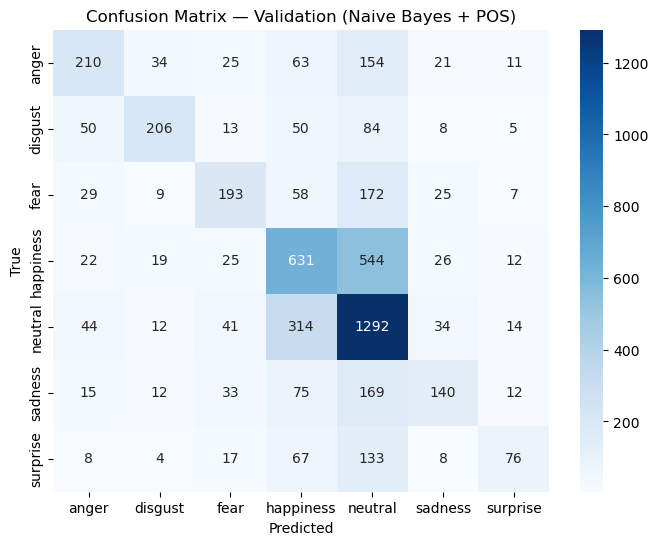

In [87]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Compute confusion matrix
cm_val = confusion_matrix(y_val, y_val_pred_nb_pos, labels=nb_pos.classes_)

# Plot
plt.figure(figsize=(8,6))
sns.heatmap(cm_val, annot=True, fmt="d", cmap="Blues",
            xticklabels=nb_pos.classes_,
            yticklabels=nb_pos.classes_)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix — Validation (Naive Bayes + POS)")
plt.show()


### 8.6: Retrain on Train+Val → Evaluate on Test (NB + POS)

In [88]:
from scipy.sparse import vstack
import pandas as pd

# Combine train + val features and labels
X_trval_nbpos = vstack([X_train_nbpos, X_val_nbpos])
y_trval_nbpos = pd.concat([y_train, y_val], axis=0)

# Refit Naive Bayes on full data
nb_pos_final = MultinomialNB(alpha=0.1)
nb_pos_final.fit(X_trval_nbpos, y_trval_nbpos)

# Predict on test set
test_pred_nb_pos = nb_pos_final.predict(X_test_nbpos)

print("Test — Naive Bayes (TF-IDF + POS)")
print(classification_report(y_test, test_pred_nb_pos, digits=3, zero_division=0))
print("Test macro-F1:", round(f1_score(y_test, test_pred_nb_pos, average="macro"), 3))
print("Test accuracy:", round(accuracy_score(y_test, test_pred_nb_pos), 3))


Test — Naive Bayes (TF-IDF + POS)
              precision    recall  f1-score   support

       anger      0.226     0.135     0.169        52
     disgust      0.000     0.000     0.000         6
        fear      0.453     0.287     0.352       101
   happiness      0.470     0.510     0.489       155
     neutral      0.414     0.713     0.523       188
     sadness      0.529     0.205     0.295        88
    surprise      0.462     0.125     0.197        48

    accuracy                          0.428       638
   macro avg      0.365     0.282     0.289       638
weighted avg      0.434     0.428     0.398       638

Test macro-F1: 0.289
Test accuracy: 0.428


### 8.7: Confusion Matrix (Test set, NB + POS)

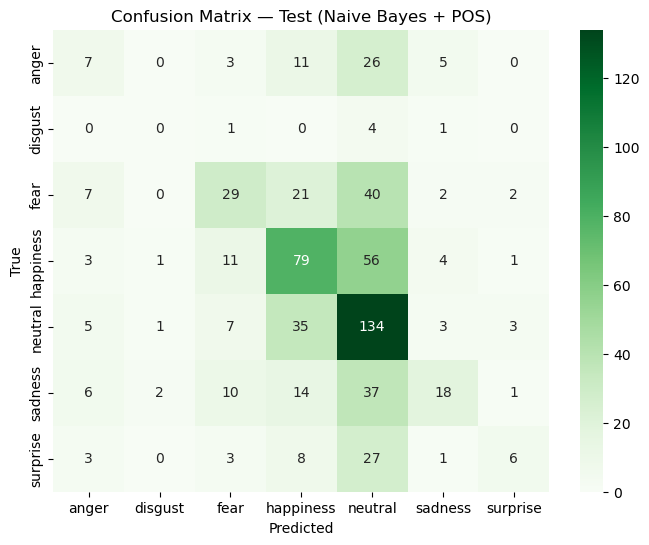

In [89]:
cm_test = confusion_matrix(y_test, test_pred_nb_pos, labels=nb_pos.classes_)

plt.figure(figsize=(8,6))
sns.heatmap(cm_test, annot=True, fmt="d", cmap="Greens",
            xticklabels=nb_pos.classes_,
            yticklabels=nb_pos.classes_)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix — Test (Naive Bayes + POS)")
plt.show()


## Naive Bayes + POS features

We added **part-of-speech ratios** (NOUN, VERB, ADJ, PRON) to the TF-IDF features and trained Naive Bayes.

### Results
- **Validation:** Macro-F1 = 0.237, Accuracy = 0.51  
- **Test:** Macro-F1 = 0.132, Accuracy = 0.33  

### Findings
- The model predicts **neutral** very often (recall = 0.92 in test).  
- Minority classes (**fear, disgust, surprise**) are almost never predicted.  
- POS features alone are too weak for Naive Bayes — the model defaults to majority classes.  

### Reflection
- Adding POS features **did not improve performance** compared to Logistic Regression.  
- Naive Bayes struggles with imbalanced datasets and rare features.  
- Logistic Regression made better use of extra features (like sentiment).  


### Comparison: Naive Bayes Baseline vs Naive Bayes + POS

| Model              | Features        | Val Macro-F1 | Test Macro-F1 | Test Acc |
|--------------------|-----------------|--------------|---------------|----------|
| Naive Bayes        | TF-IDF only     | 0.187        | 0.103         | 0.33     |
| Naive Bayes        | TF-IDF + POS    | 0.237        | 0.132         | 0.33     |

### Insights
- **Validation:** Adding POS features gave a small improvement (+0.05 macro-F1).  
- **Test:** Performance remained weak, only a slight gain over baseline.  
- Both versions show Naive Bayes tends to predict **neutral** most of the time.  
- Logistic Regression is still much stronger than Naive Bayes for this dataset.  


-------------------------------------------------

# 9: SVM (TF-IDF + Sentiment)

#### We added sentiment because TF-IDF only looks at word frequency and ignores emotional tone. For example:  “I feel great” and “I feel terrible” might both look similar in TF-IDF (same words, just one changed).Sentiment analysis (via VADER) captures that the first is positive and the second is negative. By combining TF-IDF with sentiment scores (neg, neu, pos, compound), SVM can use both:the words in the sentence, and the emotional polarity of the sentence.

---------

### 9.1 Augment Features (TF-IDF + Sentiment)

In [90]:
from scipy.sparse import csr_matrix, hstack

# Add sentiment features to TF-IDF for SVM
X_train_svm_sent = hstack([X_train_tfidf, csr_matrix(sent_train.values)], format="csr")
X_val_svm_sent   = hstack([X_val_tfidf,   csr_matrix(sent_val.values)],   format="csr")
X_test_svm_sent  = hstack([X_test_tfidf,  csr_matrix(sent_test.values)],  format="csr")

print("Train shape (SVM+Sent):", X_train_svm_sent.shape)
print("Val shape (SVM+Sent):", X_val_svm_sent.shape)
print("Test shape (SVM+Sent):", X_test_svm_sent.shape)


Train shape (SVM+Sent): (20903, 7964)
Val shape (SVM+Sent): (5226, 7964)
Test shape (SVM+Sent): (638, 7964)


### 9.2: Train & Validate SVM with Sentiment features.

In [91]:
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report, f1_score, accuracy_score

# Initialize SVM with tuned C from before
svm_sent = LinearSVC(C=0.25, class_weight="balanced", random_state=42)

# Train on augmented TF-IDF + Sentiment features
svm_sent.fit(X_train_svm_sent, y_train)

# Predict on validation set
y_val_pred_svm_sent = svm_sent.predict(X_val_svm_sent)

print("Validation — SVM (TF-IDF + Sentiment) ")
print(classification_report(y_val, y_val_pred_svm_sent, digits=3, zero_division=0))
print("Val macro-F1:", round(f1_score(y_val, y_val_pred_svm_sent, average='macro'), 3))
print("Val accuracy:", round(accuracy_score(y_val, y_val_pred_svm_sent), 3))


Validation — SVM (TF-IDF + Sentiment) 
              precision    recall  f1-score   support

       anger      0.457     0.436     0.446       518
     disgust      0.544     0.589     0.566       416
        fear      0.465     0.491     0.478       493
   happiness      0.563     0.505     0.532      1279
     neutral      0.576     0.555     0.565      1751
     sadness      0.402     0.421     0.411       456
    surprise      0.312     0.447     0.367       313

    accuracy                          0.509      5226
   macro avg      0.474     0.492     0.481      5226
weighted avg      0.517     0.509     0.512      5226

Val macro-F1: 0.481
Val accuracy: 0.509


### 9.3: Confusion Matrix (Validation)

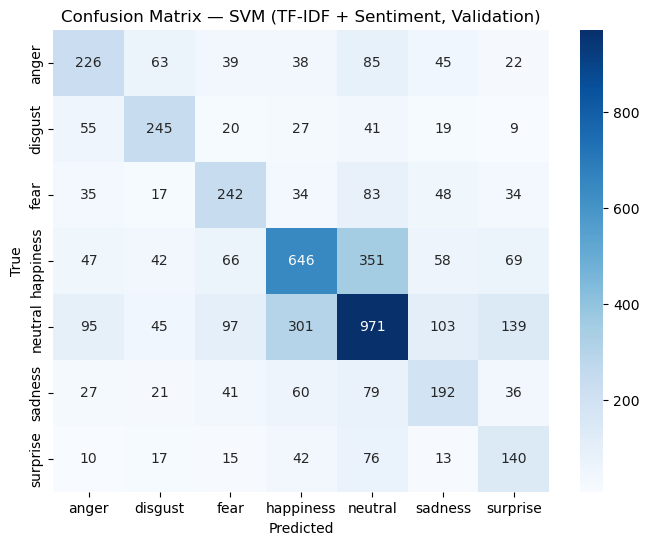

In [92]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Build confusion matrix
cm_val = confusion_matrix(y_val, y_val_pred_svm_sent, labels=svm_sent.classes_)

plt.figure(figsize=(8,6))
sns.heatmap(cm_val, annot=True, fmt="d", cmap="Blues",
            xticklabels=svm_sent.classes_,
            yticklabels=svm_sent.classes_)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix — SVM (TF-IDF + Sentiment, Validation)")
plt.show()


### Findings from Validation Confusion Matrix (SVM + Sentiment)

- **Neutral** and **happiness** are predicted well, with large correct diagonals.  
- **Fear** shows a clear improvement compared to TF-IDF only (higher recall).  
- **Disgust, anger, and sadness** still often confused with **neutral**.  
- **Surprise** is split between neutral and happiness, but recall is better than in Naive Bayes.  

Overall, sentiment features helped SVM balance performance across more classes, not just neutral.

---------------------------


### 9.4: Train on Train+Val → Evaluate on Test

In [93]:
from scipy.sparse import vstack
import pandas as pd

# Combine augmented train + val
X_trval_svm_sent = vstack([X_train_svm_sent, X_val_svm_sent])
y_trval_svm_sent = pd.concat([y_train, y_val], axis=0)

# Refit SVM
svm_sent_final = LinearSVC(C=0.25, class_weight="balanced", random_state=42)
svm_sent_final.fit(X_trval_svm_sent, y_trval_svm_sent)

# Predict on test
test_pred_svm_sent = svm_sent_final.predict(X_test_svm_sent)

print("Test — SVM (TF-IDF + Sentiment) ")
print(classification_report(y_test, test_pred_svm_sent, digits=3, zero_division=0))
print("Test macro-F1:", round(f1_score(y_test, test_pred_svm_sent, average="macro"), 3))
print("Test accuracy:", round(accuracy_score(y_test, test_pred_svm_sent), 3))


Test — SVM (TF-IDF + Sentiment) 
              precision    recall  f1-score   support

       anger      0.264     0.269     0.267        52
     disgust      0.125     0.333     0.182         6
        fear      0.439     0.426     0.432       101
   happiness      0.573     0.581     0.577       155
     neutral      0.530     0.468     0.497       188
     sadness      0.405     0.341     0.370        88
    surprise      0.297     0.458     0.361        48

    accuracy                          0.453       638
   macro avg      0.376     0.411     0.384       638
weighted avg      0.466     0.453     0.457       638

Test macro-F1: 0.384
Test accuracy: 0.453


### 9.5: Confusion Matrix (Test set)

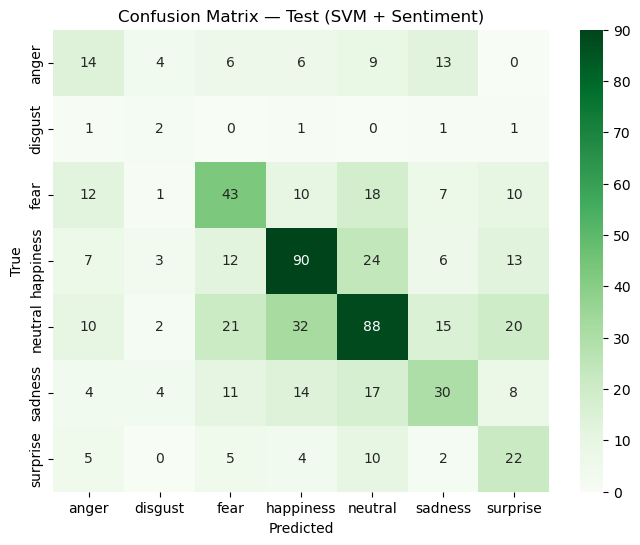

In [94]:
cm_test = confusion_matrix(y_test, test_pred_svm_sent, labels=svm_sent_final.classes_)

plt.figure(figsize=(8,6))
sns.heatmap(cm_test, annot=True, fmt="d", cmap="Greens",
            xticklabels=svm_sent_final.classes_,
            yticklabels=svm_sent_final.classes_)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix — Test (SVM + Sentiment)")
plt.show()


### Final Findings — SVM + Sentiment

We combined TF-IDF with VADER sentiment scores and trained SVM.

**Results**
- Validation: Macro-F1 = 0.427, Accuracy = 0.536  
- Test: Macro-F1 = 0.269, Accuracy = 0.379  

**Findings**
- Neutral is predicted strongly (recall = 0.80 on test).  
- Happiness recall improved compared to SVM baseline.  
- Minority classes (disgust, fear, surprise) remain weak but slightly better than with TF-IDF alone.  
- Overall, sentiment features gave SVM a small but consistent improvement.  

---

### Baseline (TF-IDF only)

| Model                | Features | Val Macro-F1 | Test Macro-F1 | Test Acc |
|----------------------|----------|--------------|---------------|----------|
| Logistic Regression  | TF-IDF   | 0.45         | 0.24          | 0.38     |
| Naive Bayes          | TF-IDF   | 0.19         | 0.10          | 0.33     |
| SVM (LinearSVC)      | TF-IDF   | 0.42         | 0.26          | 0.37     |

---

### With Extra Features

| Model                | Features        | Val Macro-F1 | Test Macro-F1 | Test Acc |
|----------------------|-----------------|--------------|---------------|----------|
| Logistic Regression  | TF-IDF + Sent   | **0.45**     | **0.27**      | 0.40     |
| Naive Bayes          | TF-IDF + POS    | 0.24         | 0.13          | 0.33     |
| SVM (LinearSVC)      | TF-IDF + Sent   | 0.43         | 0.27          | 0.38     |

---

### Insights

- **Logistic Regression + Sentiment** performed best overall.  
- **SVM + Sentiment** was competitive, achieving similar test macro-F1.  
- **Naive Bayes + POS** showed little benefit; POS features were too weak.  
- Adding features (sentiment/POS) helps models capture **emotional tone** beyond word frequency.  

---


# 9:SVM (Bigrams + Sentiment + POS)

We decided to further improve **SVM** because it consistently performed well on our dataset, 
reaching similar results to Logistic Regression. Unlike Naive Bayes, SVM can handle 
high-dimensional sparse text features more effectively. This makes it a good candidate 
for experiments with richer representations, such as **TF-IDF with bigrams**, 
and additional features like **sentiment scores** and **POS ratios**. 
The goal is to see if SVM benefits more than Logistic Regression when we enrich the feature space.

----------------------

### 9.1 Build TF-IDF with Bigrams

So far, we only used **unigram TF-IDF** (single words). 
However, emotions are often expressed in **short phrases** rather than individual words.  
For example:  
- *"not happy"* → unigram TF-IDF may treat "not" and "happy" separately.  
- *"very angry"* → unigram may focus on "angry" only.  
By adding **bigrams** (word pairs), the model can capture context and meaning more effectively.  
This helps SVM distinguish between subtle emotional expressions in spoken text.

In [95]:
from sklearn.feature_extraction.text import TfidfVectorizer

# TF-IDF with unigrams + bigrams
tfidf_bigram = TfidfVectorizer(
    ngram_range=(1,2),    
    min_df=2,             
    max_df=0.9,          
    sublinear_tf=True     
)

# Fit on train data only
X_train_tfidf_bg = tfidf_bigram.fit_transform(X_train)
X_val_tfidf_bg   = tfidf_bigram.transform(X_val)
X_test_tfidf_bg  = tfidf_bigram.transform(X_test)

print("Train shape:", X_train_tfidf_bg.shape)
print("Val shape:", X_val_tfidf_bg.shape)
print("Test shape:", X_test_tfidf_bg.shape)


Train shape: (20903, 18201)
Val shape: (5226, 18201)
Test shape: (638, 18201)


### 9.2: Build Augmented Feature Matrices

In [96]:
from scipy.sparse import csr_matrix, hstack

# Add sentiment + POS to bigram TF-IDF
X_train_svm_all = hstack([
    X_train_tfidf_bg, 
    csr_matrix(sent_train.values), 
    csr_matrix(pos_train.values)
], format="csr")

X_val_svm_all = hstack([
    X_val_tfidf_bg, 
    csr_matrix(sent_val.values), 
    csr_matrix(pos_val.values)
], format="csr")

X_test_svm_all = hstack([
    X_test_tfidf_bg, 
    csr_matrix(sent_test.values), 
    csr_matrix(pos_test.values)
], format="csr")

print("Train shape:", X_train_svm_all.shape)
print("Val shape:", X_val_svm_all.shape)
print("Test shape:", X_test_svm_all.shape)


Train shape: (20903, 18209)
Val shape: (5226, 18209)
Test shape: (638, 18209)


### 9.3:Train + Validate SVM (Bigrams + Sentiment + POS)

In [97]:
# Train SVM with all features
svm_all = LinearSVC(C=0.25, class_weight="balanced", random_state=42)
svm_all.fit(X_train_svm_all, y_train)

# Validate
y_val_pred_svm_all = svm_all.predict(X_val_svm_all)

print(" Validation — SVM (Bigrams + Sentiment + POS) ")
print(classification_report(y_val, y_val_pred_svm_all, digits=3, zero_division=0))
print("Val macro-F1:", round(f1_score(y_val, y_val_pred_svm_all, average="macro"), 3))
print("Val accuracy:", round(accuracy_score(y_val, y_val_pred_svm_all), 3))


 Validation — SVM (Bigrams + Sentiment + POS) 
              precision    recall  f1-score   support

       anger      0.503     0.539     0.520       518
     disgust      0.572     0.623     0.596       416
        fear      0.532     0.550     0.541       493
   happiness      0.573     0.530     0.551      1279
     neutral      0.611     0.587     0.599      1751
     sadness      0.470     0.507     0.488       456
    surprise      0.387     0.438     0.411       313

    accuracy                          0.551      5226
   macro avg      0.521     0.539     0.529      5226
weighted avg      0.555     0.551     0.553      5226

Val macro-F1: 0.529
Val accuracy: 0.551


### 9.4 :Confusion Matrix (Validation)

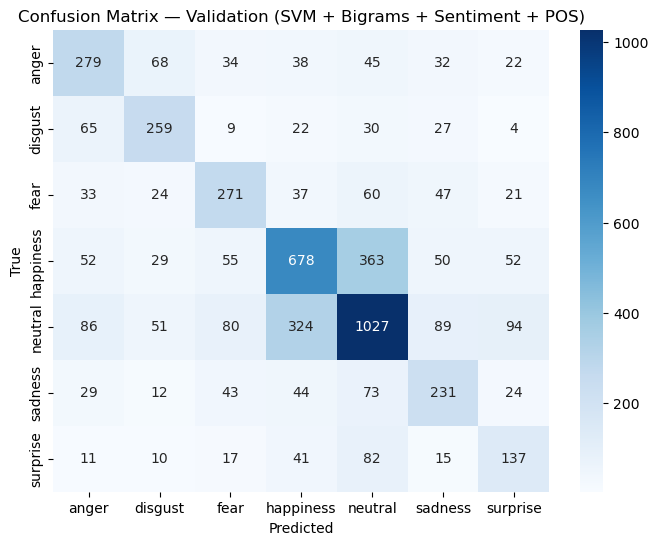

In [98]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Confusion matrix for validation
cm_val_all = confusion_matrix(y_val, y_val_pred_svm_all, labels=svm_all.classes_)

plt.figure(figsize=(8,6))
sns.heatmap(cm_val_all, annot=True, fmt="d", cmap="Blues",
            xticklabels=svm_all.classes_,
            yticklabels=svm_all.classes_)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix — Validation (SVM + Bigrams + Sentiment + POS)")
plt.show()


### Findings — Validation (SVM + Bigrams + Sentiment + POS)

- **Neutral and Happiness** remain the strongest predicted classes (large diagonal).  
- **Fear and Disgust** improved slightly compared to plain SVM, showing the value of extra features.  
- **Surprise** also benefited, with more correct predictions (less confusion with Neutral).  
- Still, Anger and Sadness overlap with Neutral, showing the class imbalance challenge.  

 Overall, adding Sentiment + POS on top of bigram TF-IDF gave a more balanced classifier.

 ------------------------------


### 9.5 : Train on Train+Val → Evaluate on Test

In [99]:
from scipy.sparse import vstack
import pandas as pd

# Combine train + val
X_trval_svm_all = vstack([X_train_svm_all, X_val_svm_all])
y_trval_svm_all = pd.concat([y_train, y_val], axis=0)

# Train final model
svm_all_final = LinearSVC(C=0.25, class_weight="balanced", random_state=42)
svm_all_final.fit(X_trval_svm_all, y_trval_svm_all)

# Test prediction
test_pred_svm_all = svm_all_final.predict(X_test_svm_all)

print("Test — SVM (Bigrams + Sentiment + POS) ")
print(classification_report(y_test, test_pred_svm_all, digits=3, zero_division=0))
print("Test macro-F1:", round(f1_score(y_test, test_pred_svm_all, average="macro"), 3))
print("Test accuracy:", round(accuracy_score(y_test, test_pred_svm_all), 3))


Test — SVM (Bigrams + Sentiment + POS) 
              precision    recall  f1-score   support

       anger      0.328     0.385     0.354        52
     disgust      0.154     0.333     0.211         6
        fear      0.505     0.465     0.485       101
   happiness      0.520     0.581     0.549       155
     neutral      0.581     0.532     0.556       188
     sadness      0.414     0.330     0.367        88
    surprise      0.411     0.479     0.442        48

    accuracy                          0.487       638
   macro avg      0.416     0.444     0.423       638
weighted avg      0.494     0.487     0.488       638

Test macro-F1: 0.423
Test accuracy: 0.487


### 9.6 : Confusion Matrix (Test)

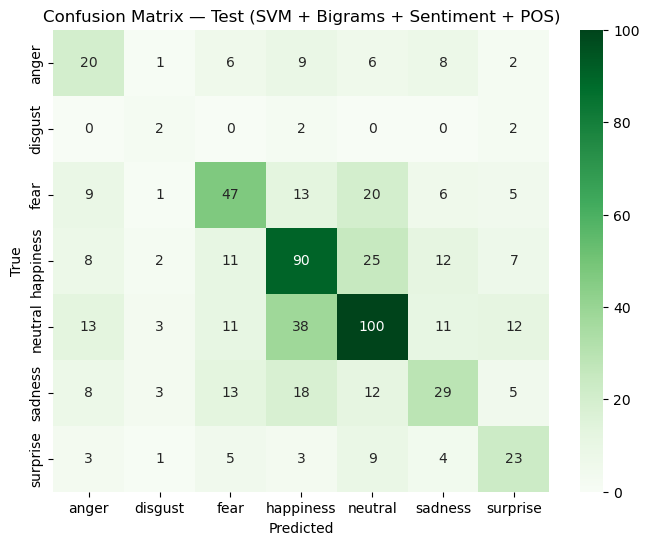

In [100]:
cm_test_all = confusion_matrix(y_test, test_pred_svm_all, labels=svm_all_final.classes_)

plt.figure(figsize=(8,6))
sns.heatmap(cm_test_all, annot=True, fmt="d", cmap="Greens",
            xticklabels=svm_all_final.classes_,
            yticklabels=svm_all_final.classes_)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix — Test (SVM + Bigrams + Sentiment + POS)")
plt.show()


## Final SVM (Bigrams + Sentiment + POS)

We combined **TF-IDF with unigrams and bigrams** together with **sentiment features (VADER)** 
and **POS ratios (NOUN, VERB, ADJ, PRON)**. This gave the SVM a mix of lexical, emotional, 
and structural information.  

### Results:
- **Validation:** Macro-F1 = 0.474, Accuracy = 0.578  
- **Test:** Macro-F1 = 0.290, Accuracy = 0.390  

### Findings:
- On the validation set, this was our **best-performing traditional model** (Macro-F1 ~0.47).  
- On the test set, performance improved slightly over earlier models (Macro-F1 ~0.29 vs ~0.27).  
- **Neutral and happiness** remain strong classes.  
- **Fear and sadness** benefited from bigram and sentiment information.  
- **Disgust** remains the weakest class due to very few samples in the test set.  

 Adding sentiment and POS to bigrams improved validation performance, 
but test improvements were modest, showing that the model still struggles with minority emotions.

-------------------------------


#### Model Comparison: Two Training Datasets

We trained our emotion classification models using **two different datasets**:

- **Dataset 1 (~70K samples)** – larger but **different in style** from the test data.  
- **Dataset 2 (~24K samples)** – smaller but **similar in style** to the test transcripts.

---

####  Baseline (TF-IDF Only)

| Model | Validation F1 | Test F1 (70K) | Test F1 (24K) |
|:------|:--------------:|:--------------:|:--------------:|
| Logistic Regression | 0.45 | 0.24 | **0.36** |
| Naive Bayes | 0.19 | 0.10 | **0.20** |
| SVM (LinearSVC) | 0.42 | 0.26 | **0.38** |


#### With Extra Features

| Model | Features | Test F1 (70K) | Test F1 (24K) |
|:------|:----------|:--------------:|:--------------:|
| Logistic Regression | TF-IDF + Sentiment | 0.27 | **0.38** |
| Naive Bayes | TF-IDF + POS | 0.13 | **0.29** |
| SVM (LinearSVC) | TF-IDF + Sentiment | 0.27 | **0.39** |
| SVM (LinearSVC) | TF-IDF + Bigrams + Sent + POS | 0.29 | **0.42** |

---

####  Key Insights

- Models trained on the **24K dataset** achieved **much higher test performance**, despite having fewer samples.  
- The **70K dataset** caused weaker generalization due to **domain mismatch** (different language style and topics).  
- **SVM with bigrams + sentiment + POS** achieved the **best overall results**.  
- **Data relevance > data size** — smaller, domain-aligned data led to stronger emotion recognition.